In [ ]:
17: 1-8 + 10 + 15

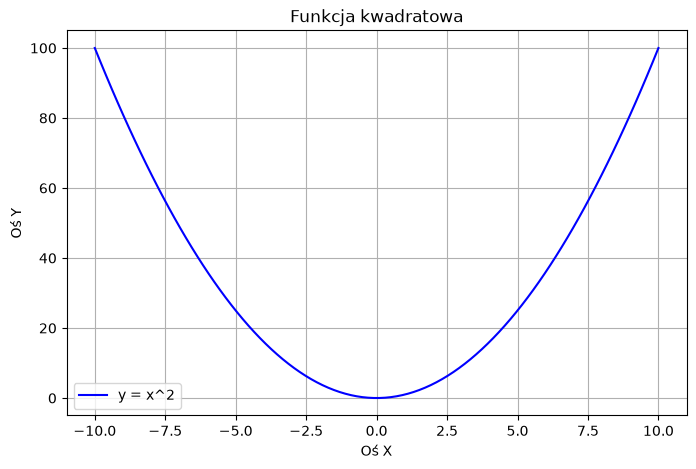

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


x = np.linspace(-10, 10, 100)
y = x**2


plt.figure(figsize=(8, 5))
plt.plot(x, y, color='blue', label='y = x^2')

# Wymagane elementy
plt.title('Funkcja kwadratowa')
plt.xlabel('Oś X')
plt.ylabel('Oś Y')
plt.grid(True)
plt.legend()

plt.show()

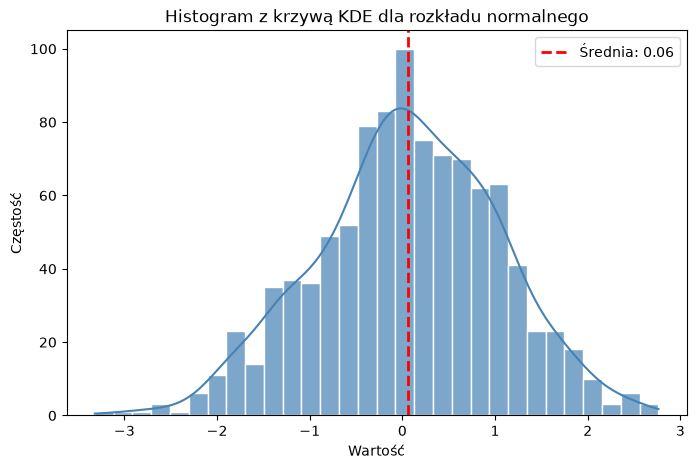

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


data = np.random.normal(loc=0, scale=1, size=1000)
mean_val = np.mean(data)

plt.figure(figsize=(8, 5))

#  histogram z KDE
sns.histplot(
    data,
    bins=30,
    kde=True,
    color='steelblue',
    alpha=0.7,
    edgecolor='white',
)

# Dodanie czerwonej, przerywanej linii dla średniej
plt.axvline(
    mean_val,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Średnia: {mean_val:.2f}',
)

plt.title('Histogram z krzywą KDE dla rozkładu normalnego')
plt.xlabel('Wartość')
plt.ylabel('Częstość')
plt.legend()

plt.show()

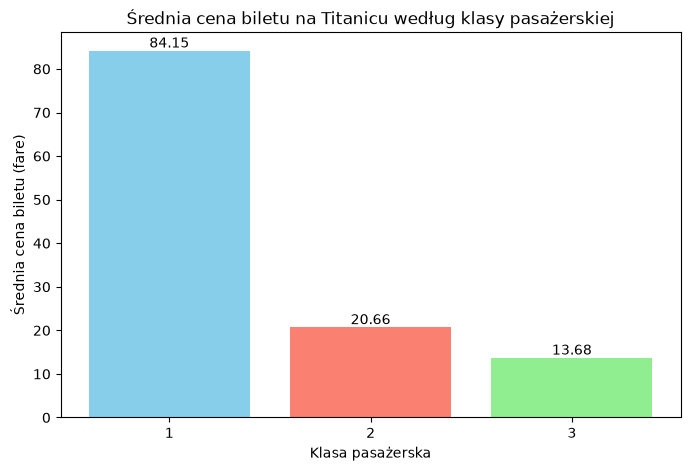

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns


titanic = sns.load_dataset('titanic')


avg_fare = titanic.groupby('pclass')['fare'].mean().reset_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(
    avg_fare['pclass'].astype(str),
    avg_fare['fare'],
    color=['skyblue', 'salmon', 'lightgreen'],
)

# Dodanie wartości na słupkach
for bar in bars:
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height,
      f'{height:.2f}',
      ha='center',
      va='bottom',
      fontsize=10,
  )

plt.title('Średnia cena biletu na Titanicu według klasy pasażerskiej')
plt.xlabel('Klasa pasażerska')
plt.ylabel('Średnia cena biletu (fare)')

plt.show()

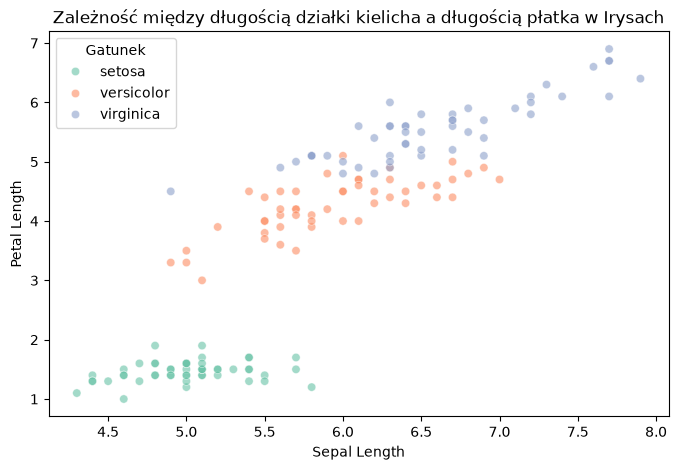

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

iris = sns.load_dataset('iris')

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=iris,
    x='sepal_length',
    y='petal_length',
    hue='species',
    palette='Set2',
    alpha=0.6,
)

plt.title(
    'Zależność między długością działki kielicha a długością płatka w Irysach'
)
plt.xlabel('Sepal Length')
plt.ylabel('Petal Length')
plt.legend(title='Gatunek')

plt.show()

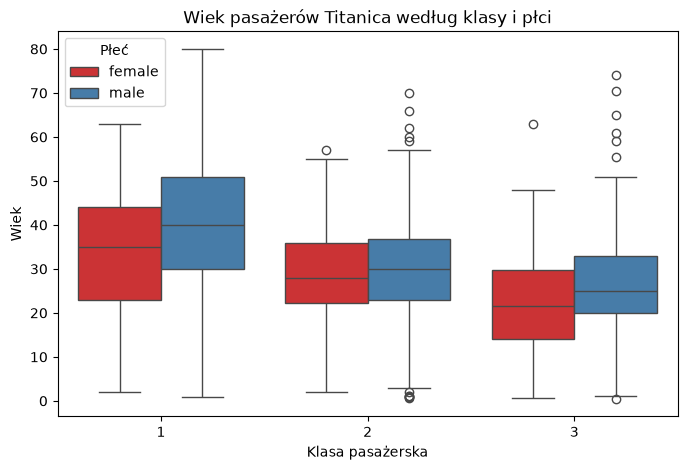

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns


titanic = sns.load_dataset('titanic')

plt.figure(figsize=(8, 5))
sns.boxplot(data=titanic, x='pclass', y='age', hue='sex', palette='Set1')

plt.title('Wiek pasażerów Titanica według klasy i płci')
plt.xlabel('Klasa pasażerska')
plt.ylabel('Wiek')
plt.legend(title='Płeć')

plt.show()

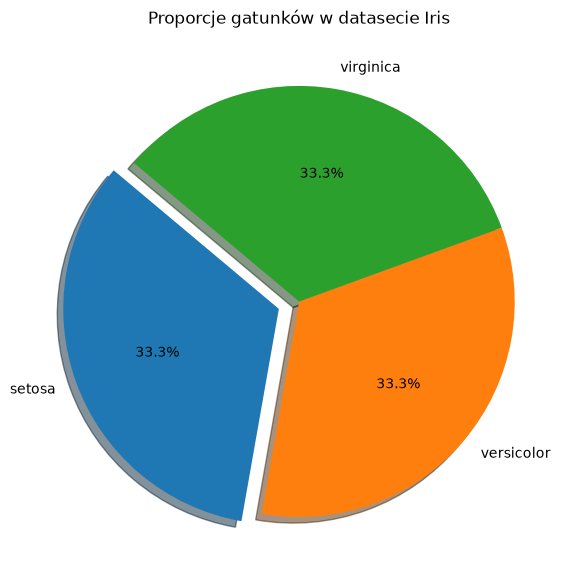

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


iris = sns.load_dataset('iris')
species_counts = iris['species'].value_counts()


explode = [0.1 if i == species_counts.idxmax() else 0 for i in species_counts.index]

plt.figure(figsize=(7, 7))
plt.pie(
    species_counts,
    labels=species_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    explode=explode,
    shadow=True,
)

plt.title('Proporcje gatunków w datasecie Iris')

plt.show()

C:\Users\czeralpl\AppData\Local\Temp\ipykernel_5508\2279307241.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tips, x='day', y='tip', ax=axes[1, 1], palette='Set2')


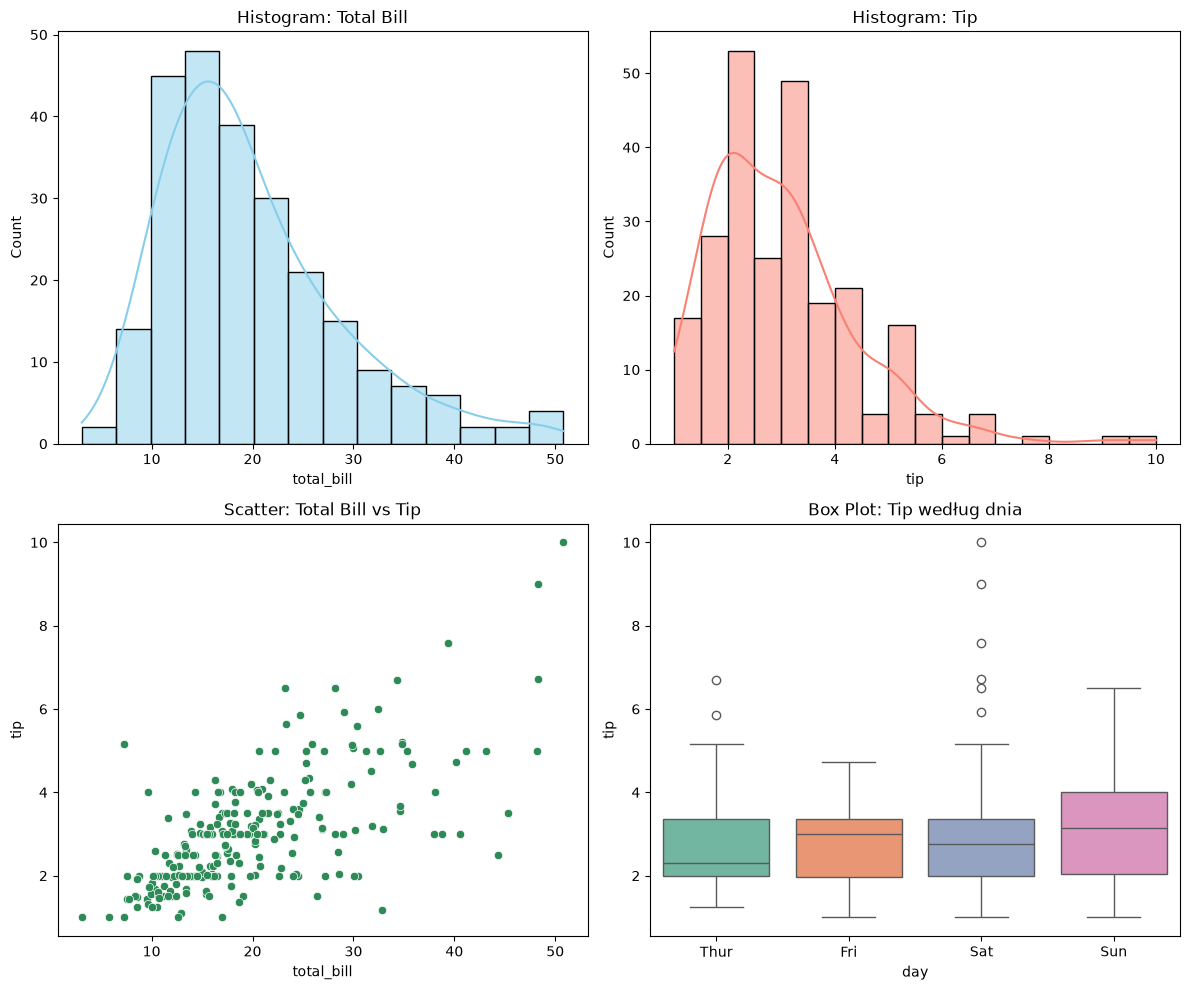

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


tips = sns.load_dataset('tips')

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. total_bill
sns.histplot(tips['total_bill'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Histogram: Total Bill')

# 2. tip
sns.histplot(tips['tip'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Histogram: Tip')

# 3. total_bill vs tip
sns.scatterplot(
    data=tips, x='total_bill', y='tip', ax=axes[1, 0], color='seagreen'
)
axes[1, 0].set_title('Scatter: Total Bill vs Tip')


sns.boxplot(data=tips, x='day', y='tip', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Box Plot: Tip według dnia')

plt.tight_layout()
plt.show()

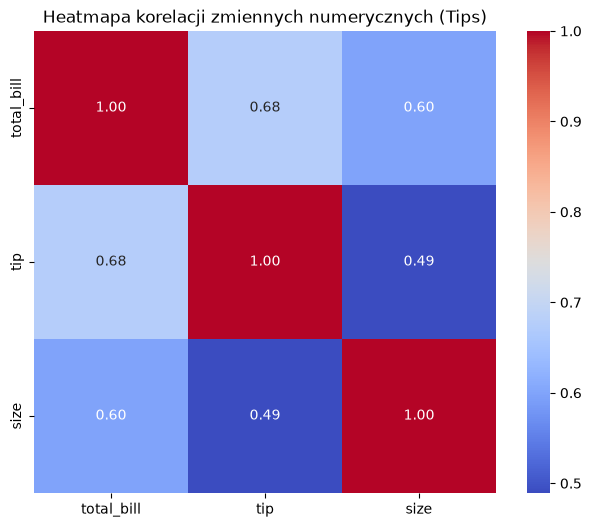

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns


tips = sns.load_dataset('tips')
numeric_tips = tips.select_dtypes(include=['float64', 'int64'])
corr = numeric_tips.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, cbar=True
)

plt.title('Heatmapa korelacji zmiennych numerycznych (Tips)')

plt.show()

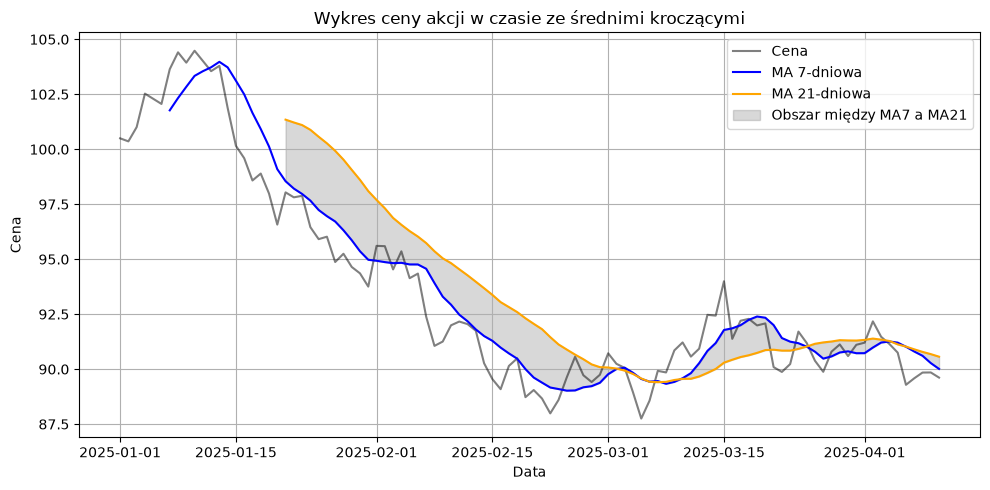

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


np.random.seed(42)
dates = pd.date_range('2025-01-01', periods=100)
price = 100 + np.cumsum(np.random.randn(100))
df = pd.DataFrame({'date': dates, 'price': price})

df['MA7'] = df['price'].rolling(window=7).mean()
df['MA21'] = df['price'].rolling(window=21).mean()


plt.figure(figsize=(10, 5))

# Główna linia ceny
plt.plot(df['date'], df['price'], label='Cena', color='black', alpha=0.5)

# Linie średnich kroczących
plt.plot(df['date'], df['MA7'], label='MA 7-dniowa', color='blue', linewidth=1.5)
plt.plot(
    df['date'], df['MA21'], label='MA 21-dniowa', color='orange', linewidth=1.5
)

# Zacieniony obszar między MA7 a MA21
plt.fill_between(
    df['date'],
    df['MA7'],
    df['MA21'],
    color='gray',
    alpha=0.3,
    label='Obszar między MA7 a MA21',
)


plt.title('Wykres ceny akcji w czasie ze średnimi kroczącymi')
plt.xlabel('Data')
plt.ylabel('Cena')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

Stwórz interaktywny dashboard Plotly z 4 wykresami (make_subplots):
Wykres świecowy (candlestick) ceny
Wykres wolumenu (bar chart)
RSI indicator (14-dniowy)
Histogram dziennych stóp zwrotu
Dane: wygeneruj symulowane dane OHLCV (Open, High, Low, Close, Volume)

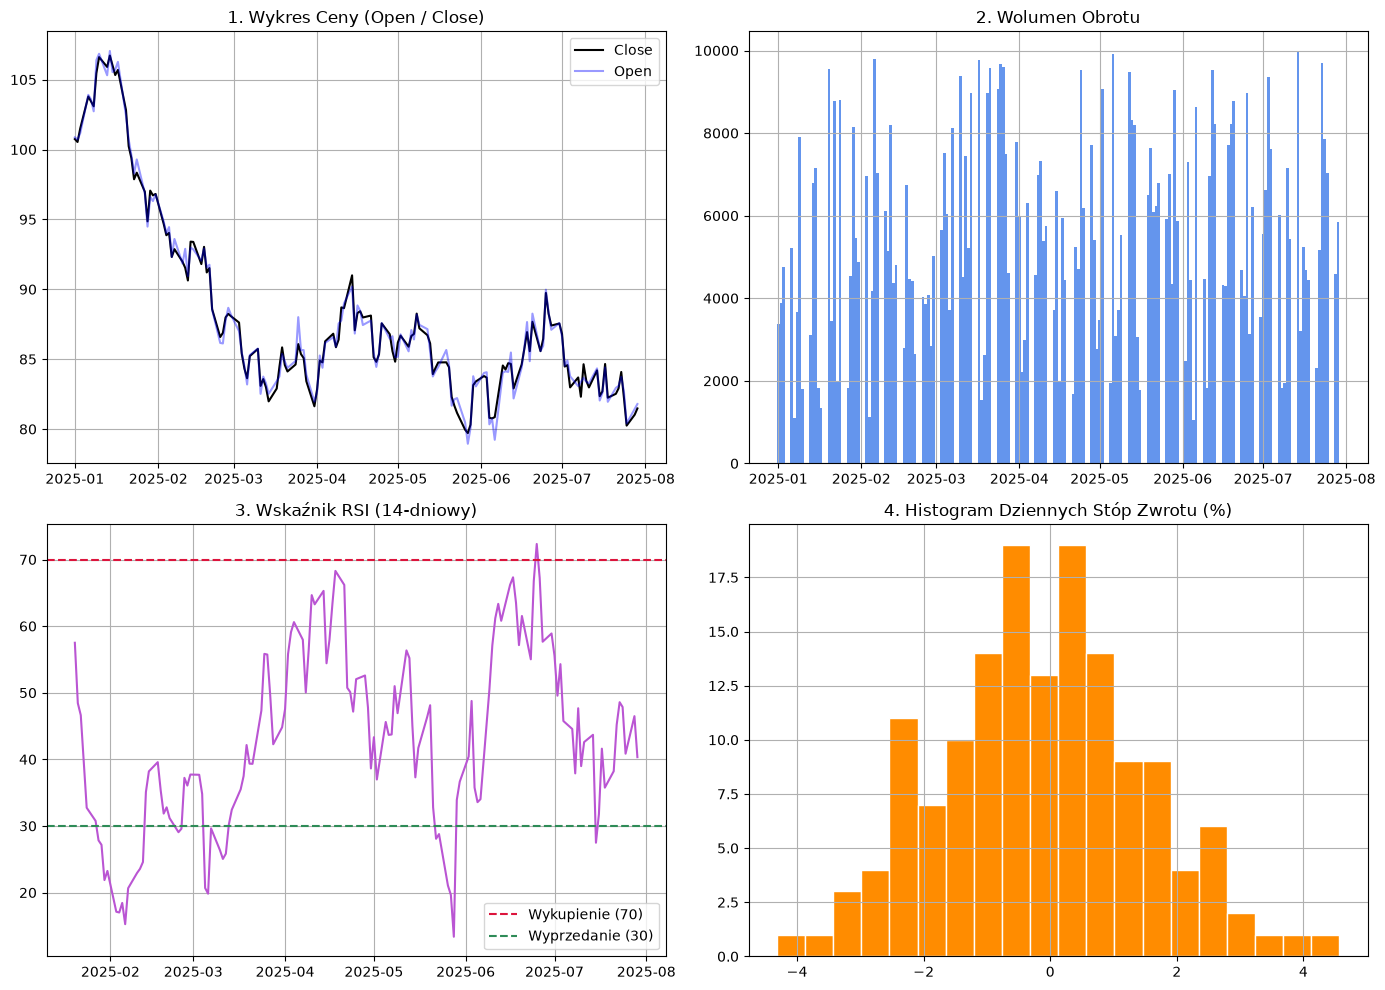

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


np.random.seed(42)
n = 150
dates = pd.date_range(start='2025-01-01', periods=n, freq='B')

close = 100 + np.cumsum(np.random.randn(n) * 1.5)
open_p = close + np.random.randn(n) * 0.5
high = np.maximum(open_p, close) + np.abs(np.random.randn(n) * 1)
low = np.minimum(open_p, close) - np.abs(np.random.randn(n) * 1)
volume = np.random.randint(1000, 10000, size=n)

df = pd.DataFrame(
    {
        'Date': dates,
        'Open': open_p,
        'High': high,
        'Low': low,
        'Close': close,
        'Volume': volume,
    }
)


#  RSI (14-dniowego)
def calculate_rsi(data, window=14):
#   Oblicza zmianę ceny między bieżącym a poprzednim dniem (różnicę wartości).
  delta = data.diff() 
  gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
  loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
  rs = gain / loss
  return 100 - (100 / (1 + rs))


df['RSI'] = calculate_rsi(df['Close'], 14)

#  Obliczenie dziennych stóp zwrotu (%)
df['Returns'] = df['Close'].pct_change() * 100

# 
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#  Cena (Open vs Close) ---
axes[0, 0].plot(df['Date'], df['Close'], color='black', label='Close')
axes[0, 0].plot(df['Date'], df['Open'], color='blue', alpha=0.4, label='Open')
axes[0, 0].set_title('1. Wykres Ceny (Open / Close)')
axes[0, 0].legend()
axes[0, 0].grid(True)

#  Wolumen ---
axes[0, 1].bar(df['Date'], df['Volume'], color='cornflowerblue', width=1)
axes[0, 1].set_title('2. Wolumen Obrotu')
axes[0, 1].grid(True)

#  RSI ---
axes[1, 0].plot(df['Date'], df['RSI'], color='mediumorchid', linewidth=1.5)
axes[1, 0].axhline(
    70, color='crimson', linestyle='--', label='Wykupienie (70)'
)
axes[1, 0].axhline(30, color='seagreen', linestyle='--', label='Wyprzedanie (30)')
axes[1, 0].set_title('3. Wskaźnik RSI (14-dniowy)')
axes[1, 0].legend()
axes[1, 0].grid(True)

# Histogram stóp zwrotu ---
axes[1, 1].hist(
    df['Returns'].dropna(), bins=20, color='darkorange', edgecolor='white'
)
axes[1, 1].set_title('4. Histogram Dziennych Stóp Zwrotu (%)')
axes[1, 1].grid(True)


plt.tight_layout()
plt.show()